# Pregunta 2: segmentación de agua Sentinel-1

U-Net propia VV/VH, seis ablaciones y evaluación geográfica en Bolivia. Este notebook importa el paquete y consulta resultados persistidos; no duplica el entrenamiento.


## Configuración y decisiones previas

Semilla 42, hasta 50 épocas y paciencia 10. Los resultados científicos y smoke usan directorios diferentes. Para ejecución completa se recomienda el comando del README.


In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import display, Image
from neural_exam.config import PROJECT_ROOT, load_settings
from neural_exam.cli import doctor
from neural_exam.common.io import read_json
from neural_exam.common.locking import execution_lock
from neural_exam.flood.data import prepare
from neural_exam.flood.pipeline import run
from neural_exam.flood.reporting import prepare_report_assets

RUN_PREPARE = False
RUN_TRAINING = False
RESUME = False
GENERATE_REPORT_ASSETS = False
settings = load_settings(PROJECT_ROOT / 'configs/flood.toml')
task = 'flood'
output = settings.output_root / task


## Diagnóstico sin operaciones GPU

La comprobación CUDA se realizará por separado mediante doctor --gpu-check. Esta celda consulta versiones y rutas.


In [2]:
diagnostics = doctor(settings, gpu_check=False)
display({
    'dependencies': {k: v for k, v in diagnostics['dependencies'].items() if k in ('torch', 'torchvision', 'rasterio', 'scikit-learn')},
    'flood_root': diagnostics['locations']['flood_root'],
    'output_root': diagnostics['locations']['output_root'],
    'cuda_check': 'Recorded separately in audit/doctor.log',
})


{'dependencies': {'torch': '2.10.0+cu128',
  'torchvision': '0.25.0+cu128',
  'rasterio': '1.4.3',
  'scikit-learn': '1.9.1'},
 'flood_root': '/datasets/Sen1Floods11',
 'output_root': '/outputs',
 'cuda_check': 'Recorded separately in audit/doctor.log'}

## Integridad y preparación

Bolivia se excluye de entrenamiento y estadísticas. Los píxeles sin datos no entran en pérdidas ni métricas.

Activar RUN_PREPARE únicamente después de completar las descargas y extracción. Preparar lee datos y escribe derivados locales.


In [3]:
manifest = None
if RUN_PREPARE:
    with execution_lock(settings.output_root):
        manifest = prepare(settings)
elif (output / 'manifest.json').is_file():
    manifest = read_json(output / 'manifest.json')
else:
    print('Preparación pendiente: no hay manifiesto de datos.')


## Inventario de particiones

Los conteos provienen del manifiesto real; no se usan números simulados.


In [4]:
if manifest:
    inventory = []
    for split, records in manifest['records'].items():
        valid = sum(record['valid_pixels'] for record in records)
        water = sum(record['water_pixels'] for record in records)
        inventory.append({'partition': split, 'chips': len(records), 'valid_pixels': valid, 'water_fraction': water / valid})
    display(pd.DataFrame(inventory))
    display({'band_order': manifest['band_order'], 'mean': manifest['mean'], 'std': manifest['std'],
             'normalization_source': manifest['normalization_source'], 'excluded': manifest['excluded'],
             'alignment_atol': manifest['alignment_absolute_tolerance']})


,partition,chips,valid_pixels,water_fraction
0,train,251,57017597,0.095526
1,val,86,20274154,0.110052
2,test,88,20443959,0.123020
3,bolivia,15,2824434,0.159997
4,weak,4150,1069346608,0.168311


{'band_order': ['VV', 'VH'],
 'mean': [-10.455064161886204, -17.325308892562283],
 'std': [4.06613688848822, 4.791758381768977],
 'normalization_source': 'gold training chips only',
 'excluded': {'bolivia': 0, 'gold_overlap': 0, 'weak_limit': 0},
 'alignment_atol': 1e-12}

## Experimentos

Esta celda importa la implementación del paquete. No duplica arquitectura, entrenamiento o evaluación. No ejecutar simultáneamente con otros entrenamientos.


In [5]:
if RUN_TRAINING:
    with execution_lock(settings.output_root):
        experiment_summary = run(settings, resume=RESUME, quick=False, manifest=manifest)
    display(experiment_summary)
else:
    print('Entrenamiento automático desactivado; se consultan los resultados persistidos.')


Entrenamiento automático desactivado; se consultan los resultados persistidos.


## Evaluación y revisión

Revisar IoU promedio por chip y métricas globales; documentar tres tipos de fallo SAR con evidencia.

No elegir hiperparámetros por rendimiento de prueba. Una métrica ND debe conservarse como indefinida.


In [6]:
experiments_path = output / 'experiments.csv'
if experiments_path.is_file():
    experiments = pd.read_csv(experiments_path)
    assert len(experiments) == 6, 'The scientific ablation matrix is incomplete.'
    display(experiments)
    details = []
    for experiment in experiments['experiment']:
        for split in ('test', 'bolivia'):
            scores = read_json(output / experiment / split / 'metrics.json')
            details.append({'experiment': experiment, 'split': split, 'mean_chip_iou': scores['mean_chip_iou'],
                            'reference_mean_chip_iou': scores['reference_mean_chip_iou'],
                            'defined_iou_chips': scores['defined_iou_chips'], 'empty_union_chips': scores['empty_union_chips'],
                            **scores['pooled_pixels']})
    display(pd.DataFrame(details))
    resources_path = settings.output_root / 'reports/flood/resources.csv'
    if resources_path.is_file():
        display(pd.read_csv(resources_path))
else:
    print('No completed scientific experiments are available yet.')


,experiment,test_iou,bolivia_iou,geographic_gap
0,gold_bce,0.393927,0.455477,-0.061550
1,gold_dice,0.409981,0.446339,-0.036359
2,gold_combined,0.406751,0.405720,0.001031
3,gold_weak_bce,0.325065,0.269045,0.056020
4,gold_weak_dice,0.348747,0.478984,-0.130237
5,gold_weak_combined,0.359350,0.451141,-0.091791


,experiment,split,mean_chip_iou,reference_mean_chip_iou,defined_iou_chips,empty_union_chips,tp,fp,fn,tn,valid_pixels,iou,precision,recall,f1,omission,commission
0,gold_bce,test,0.393927,0.407701,86,2,1884956,322880,630052,17606071,20443959,0.664211,0.853757,0.749483,0.798229,0.250517,0.146243
1,gold_bce,bolivia,0.455477,0.455477,15,0,345325,57471,106576,2315062,2824434,0.677943,0.857320,0.764161,0.808064,0.235839,0.142680
2,gold_dice,test,0.409981,0.409981,88,0,1988870,557753,526138,17371198,20443959,0.647258,0.780983,0.790801,0.785861,0.209199,0.219017
3,gold_dice,bolivia,0.446339,0.446339,15,0,339238,79376,112663,2293157,2824434,0.638533,0.810384,0.750691,0.779396,0.249309,0.189616
4,gold_combined,test,0.406751,0.406751,88,0,1932436,408227,582572,17520724,20443959,0.661061,0.825593,0.768362,0.795950,0.231638,0.174407
5,gold_combined,bolivia,0.405720,0.405720,15,0,297944,57925,153957,2314608,2824434,0.584403,0.837229,0.659313,0.737695,0.340687,0.162771
6,gold_weak_bce,test,0.325065,0.355744,84,4,1819054,467583,695954,17461368,20443959,0.609891,0.795515,0.723280,0.757680,0.276720,0.204485
7,gold_weak_bce,bolivia,0.269045,0.269045,15,0,226886,20124,225015,2352409,2824434,0.480665,0.918530,0.502070,0.649256,0.497930,0.081470
8,gold_weak_dice,test,0.348747,0.356147,87,1,1909144,719742,605864,17209209,20443959,0.590198,0.726218,0.759101,0.742295,0.240899,0.273782
9,gold_weak_dice,bolivia,0.478984,0.478984,15,0,380844,78304,71057,2294229,2824434,0.718296,0.829458,0.842760,0.836056,0.157240,0.170542


,experiment,epochs,best_epoch,steps,minutes,vram_gib
0,gold_bce,50,47,63,3.268697,3.145677
1,gold_dice,41,31,63,2.690289,3.145677
2,gold_combined,50,49,63,3.301166,3.145677
3,gold_weak_bce,38,28,1101,28.560032,3.146653
4,gold_weak_dice,11,1,1101,8.262285,3.145677
5,gold_weak_combined,22,12,1101,16.598343,3.146653


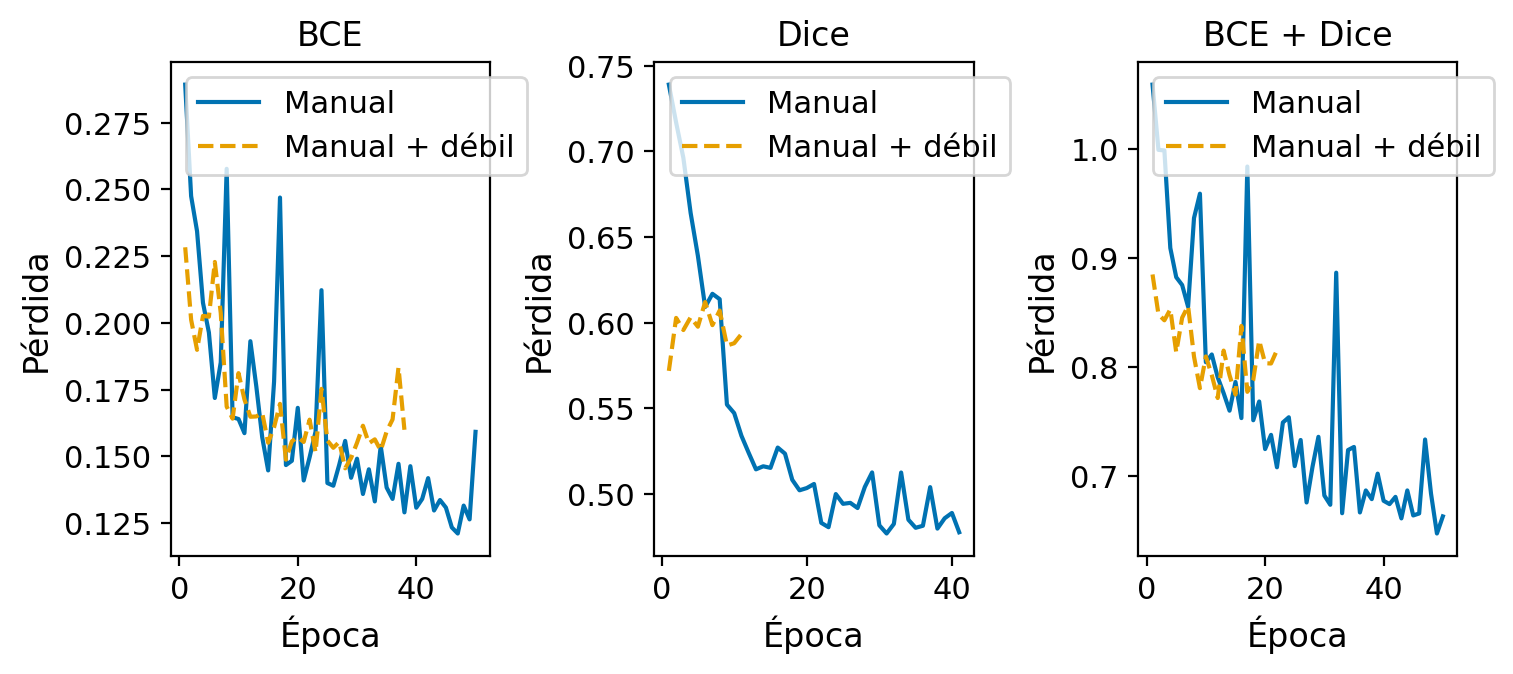

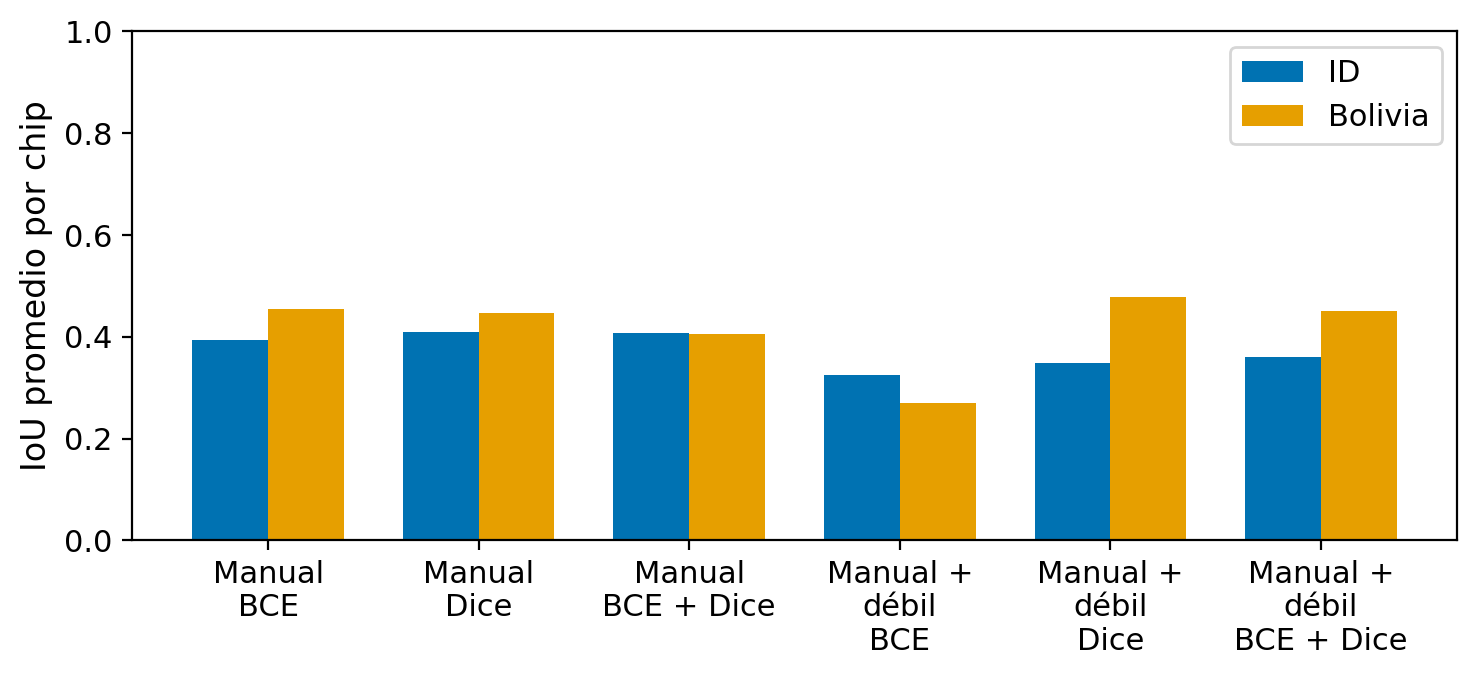

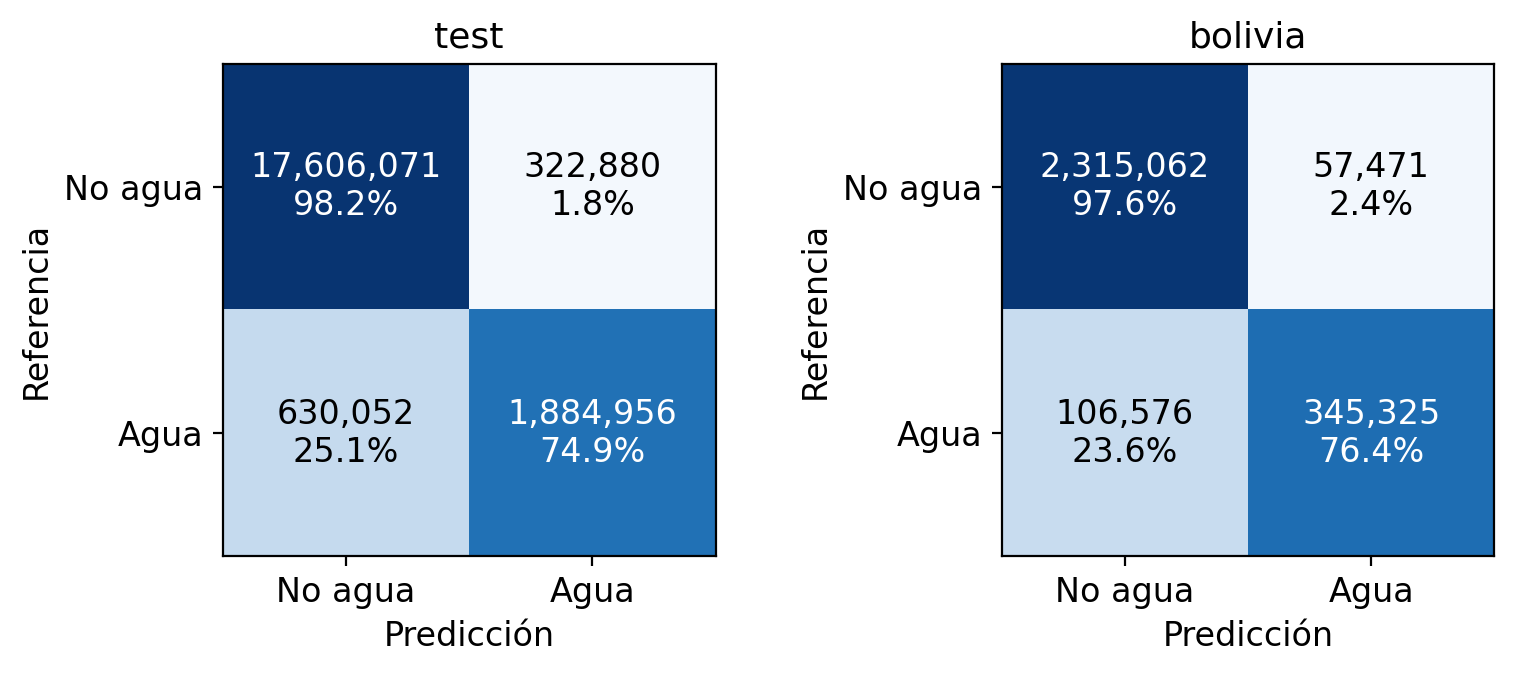

,chip_id,hypothesis,visual_evidence
6,Pakistan_70625,Superficies de baja retrodispersión pueden con...,Se predicen manchas extensas en zonas oscuras ...
7,Pakistan_849790,Agua con respuesta SAR distinta del agua abier...,La referencia cubre gran parte del chip pero l...


,chip_id,hypothesis,visual_evidence
4,Bolivia_379434,Resolución efectiva y contexto pueden degradar...,En el cauce sinuoso derecho aparecen bandas ce...


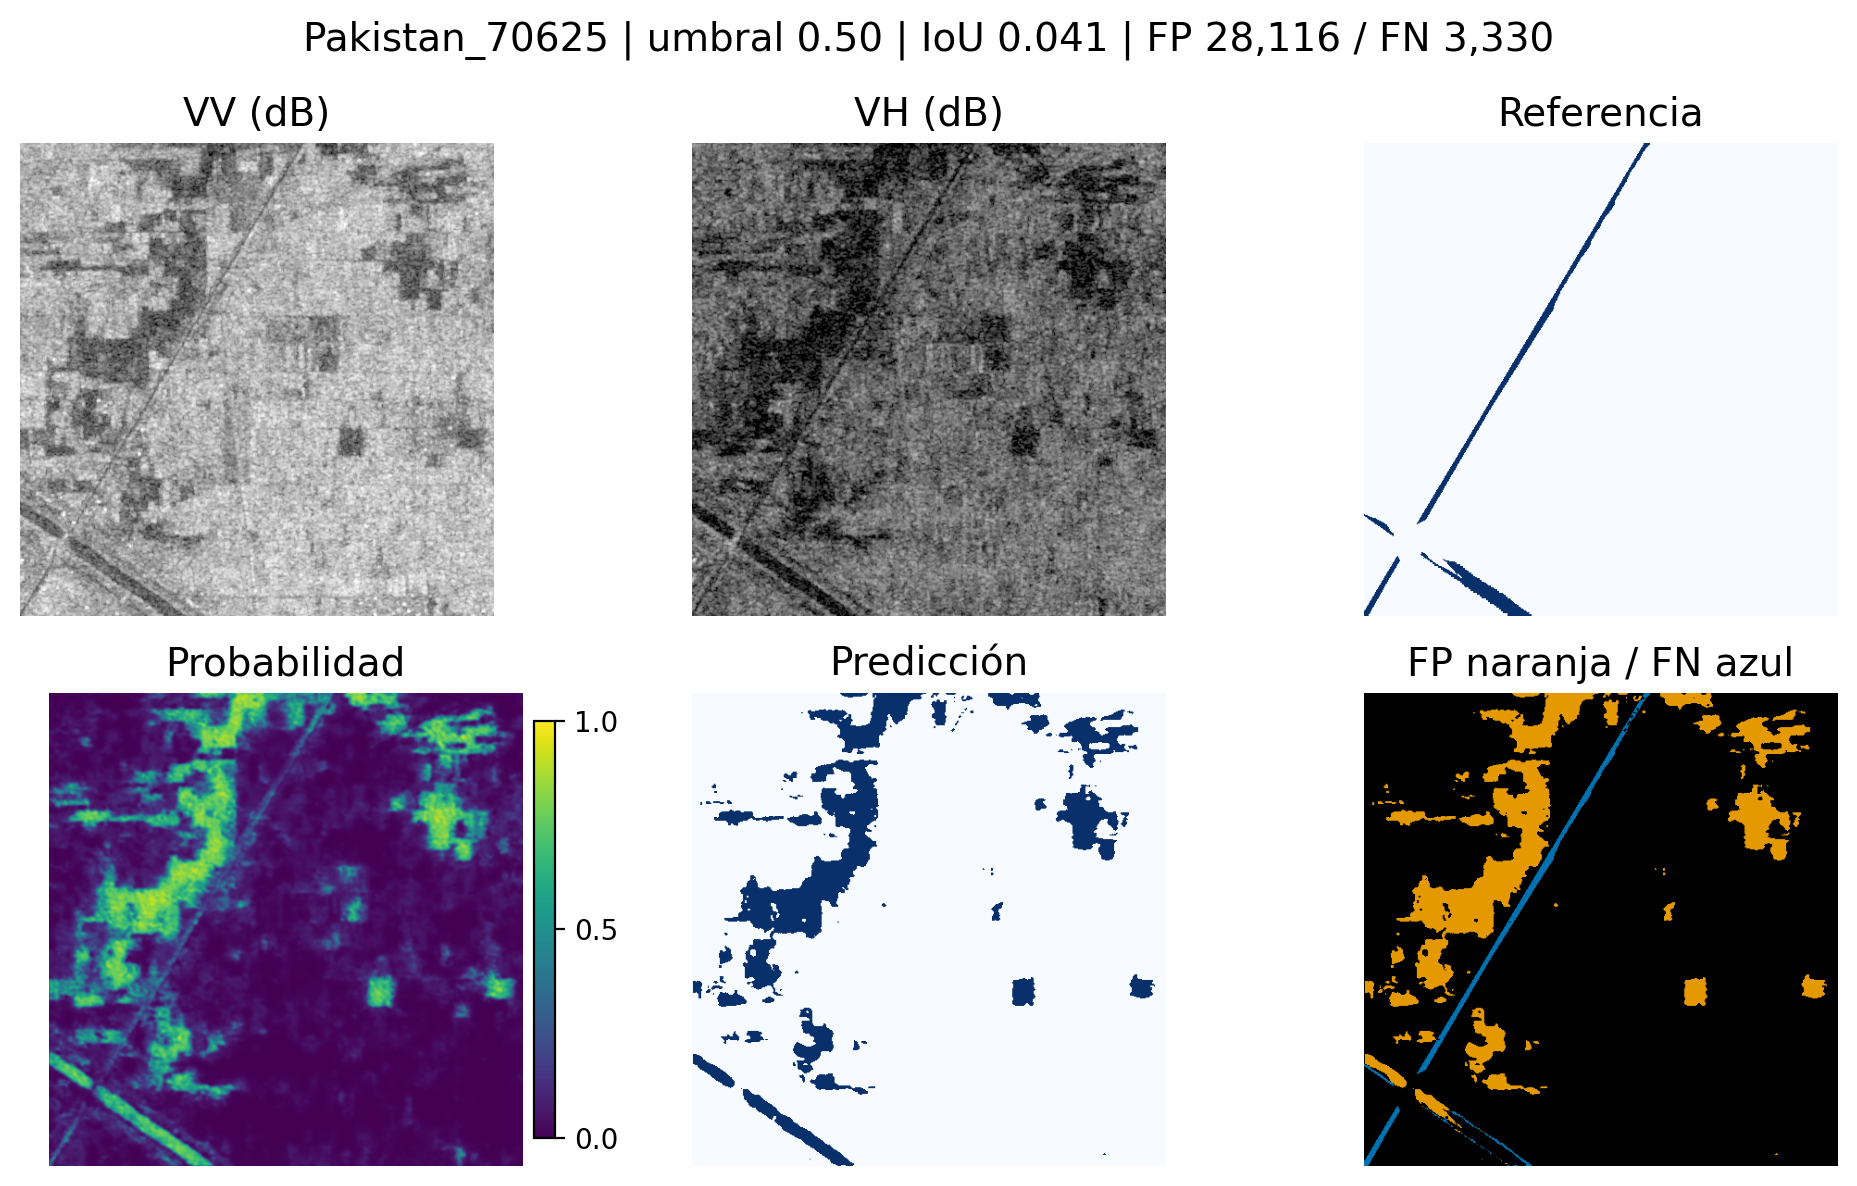

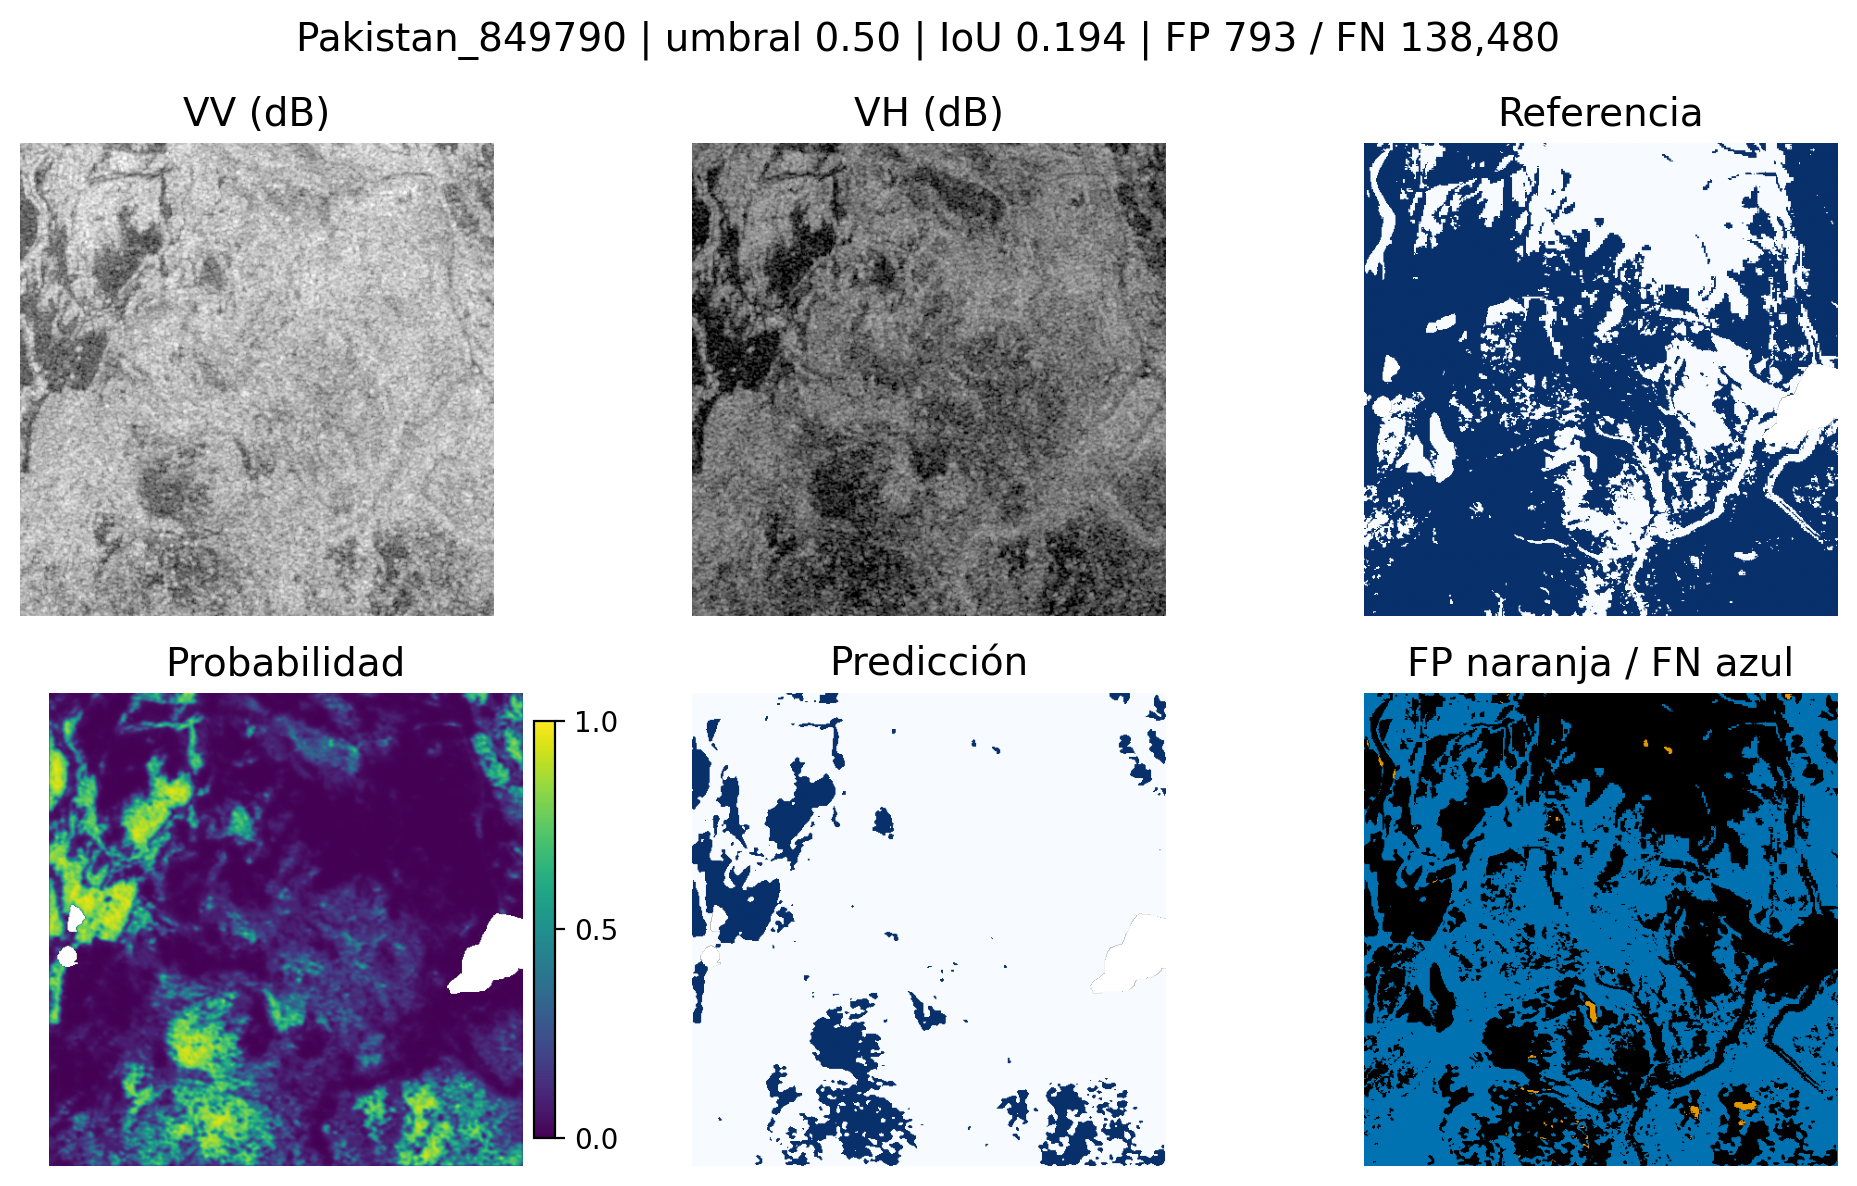

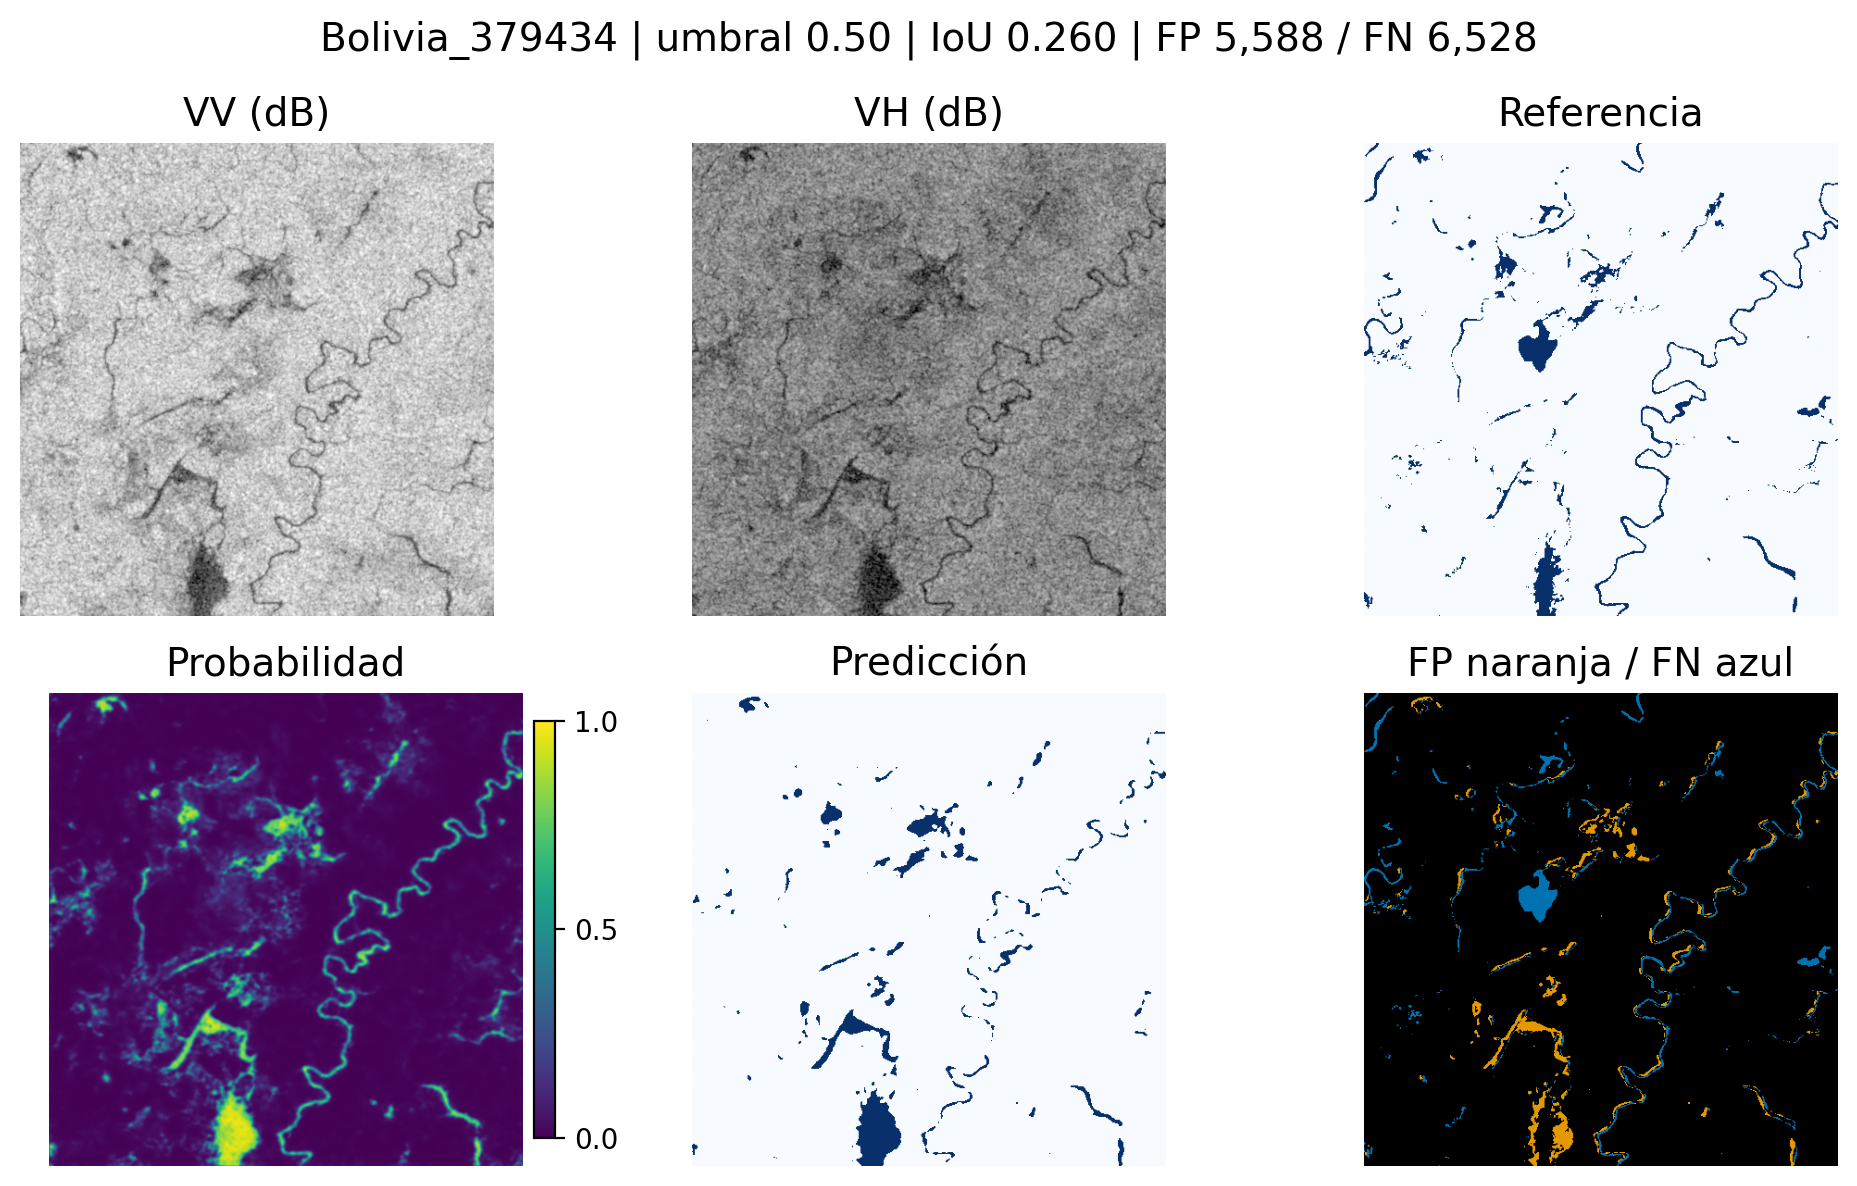

In [7]:
report_root = settings.output_root / 'reports/flood'
for name in ('validation_curves.png', 'ablation.png', 'confusion_baseline.png'):
    path = report_root / name
    if path.is_file():
        display(Image(filename=str(path), width=900))
for split in ('test', 'bolivia'):
    review = output / 'gold_bce' / split / 'qualitative_review.csv'
    if review.is_file():
        frame = pd.read_csv(review).fillna('')
        display(frame[frame['visual_evidence'] != ''])

for path in sorted((report_root / 'figures').glob('flood_*.png'))[3:6]:
    display(Image(filename=str(path), width=900))


## Fuentes del informe

Las tablas y figuras se exportan desde ejecuciones reales. Completar la discusión y la revisión humana antes de compilar el informe final.


In [8]:
if GENERATE_REPORT_ASSETS:
    display(prepare_report_assets(settings))


## Interpretación y límites

IoU promedio por chip y IoU agrupada por píxeles responden a agregaciones distintas. La versión de referencia oficial usa epsilon y asigna uno a la unión vacía; aquí se registra también el promedio sobre chips definidos, junto con su soporte.

La selección de checkpoints usa únicamente validación manual. Bolivia no interviene en ajuste, umbral ni parada temprana. Las seis configuraciones usan una semilla; agregar débiles modifica el volumen y número de pasos de entrenamiento, además de la procedencia de etiquetas.

Las observaciones de fallos deben asociarse con ejemplos reales. Sombra, doble rebote o cambios de cobertura son hipótesis físicas que dos bandas SAR no demuestran por sí solas. La discusión final se conserva en el informe de flood.
